# Task 4 — Full dataset EDA

This notebook profiles the provided train/test metadata, class balance, row-order patterns, and (when image folders are available) a deterministic sample of image integrity, dimensions, representative examples, and color statistics. It never reads test labels or fits a model.

Run from `task4/`. Figures are saved under `assets/eda/` at 300 dpi. If the local checkout contains only CSV metadata, the image-specific cells report that image files are unavailable and continue normally.

In [1]:
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from PIL import Image

cwd = Path.cwd()
local_roots = [cwd, *cwd.parents, cwd / "task4"]
local_data = next(
    (root / "data" for root in local_roots if (root / "data" / "train.csv").is_file()),
    None,
)
kaggle_data = Path("/kaggle/input/datasets/microhum/cpe333-task-4-dataset")
if local_data is not None:
    DATA_DIR = local_data
    PROJECT_DIR = local_data.parent
elif (kaggle_data / "train.csv").is_file():
    DATA_DIR = kaggle_data
    PROJECT_DIR = Path("/kaggle/working")
else:
    raise FileNotFoundError(
        "Could not find task4/data/train.csv or the attached Kaggle dataset."
    )

ASSETS_DIR = PROJECT_DIR / "assets" / "eda"
ASSETS_DIR.mkdir(parents=True, exist_ok=True)
CLASS_ORDER = ["7-11k", "fiven", "freefried", "pube", "roblock"]
CLASS_DISPLAY = {
    "7-11k": "7-11 Knights",
    "fiven": "FiveN",
    "freefried": "Free Fried",
    "pube": "PUBE",
    "roblock": "Roblock",
}
plt.rcParams.update({"font.size": 10, "figure.dpi": 120})

train = pd.read_csv(DATA_DIR / "train.csv", dtype={"id": "string"})
assert "id" in train.columns, "train.csv must contain id"
label_column = "class" if "class" in train.columns else "label"
assert label_column in train.columns, "train.csv must contain class/label"
train = train.rename(columns={label_column: "class"})
train["class"] = train["class"].astype("string").str.strip().str.lower()
if train["class"].dropna().isin([str(i) for i in range(5)]).all():
    numeric_labels = dict(enumerate(CLASS_ORDER))
    train["class"] = train["class"].astype(int).map(numeric_labels).astype("string")
test_header = pd.read_csv(DATA_DIR / "test.csv", nrows=0).columns.tolist()
test_columns = [column for column in ["id", "file_name"] if column in test_header]
assert "id" in test_columns, "test.csv must contain id"
test = pd.read_csv(DATA_DIR / "test.csv", usecols=test_columns, dtype={"id": "string"})
assert train["id"].notna().all() and test["id"].notna().all()
assert train["id"].is_unique and test["id"].is_unique
assert train["class"].notna().all()
assert set(train["class"].unique()) == set(CLASS_ORDER), (
    train["class"].value_counts().to_dict()
)
print(f"Data directory: {DATA_DIR.resolve()}")
print(
    f"Train: {train.shape[0]:,} rows × {train.shape[1]} columns; test metadata: {len(test):,} rows × {test.shape[1]} columns"
)
print("Training columns:", train.columns.tolist())
print(
    "Test columns loaded (test labels intentionally excluded):", test.columns.tolist()
)

Data directory: C:\Users\Gunte\Workspace\Workspace\works\CPE\ml00x\task4\data
Train: 31,546 rows × 2 columns; test metadata: 25,889 rows × 1 columns
Training columns: ['id', 'class']
Test columns loaded (test labels intentionally excluded): ['id']


,class,display_name,count,share
0,7-11k,7-11 Knights,12429,0.393996
1,fiven,FiveN,4407,0.139701
2,freefried,Free Fried,5596,0.177392
3,pube,PUBE,5926,0.187853
4,roblock,Roblock,3188,0.101059


Train/test ID overlap: 0; class imbalance ratio (largest/smallest): 3.899


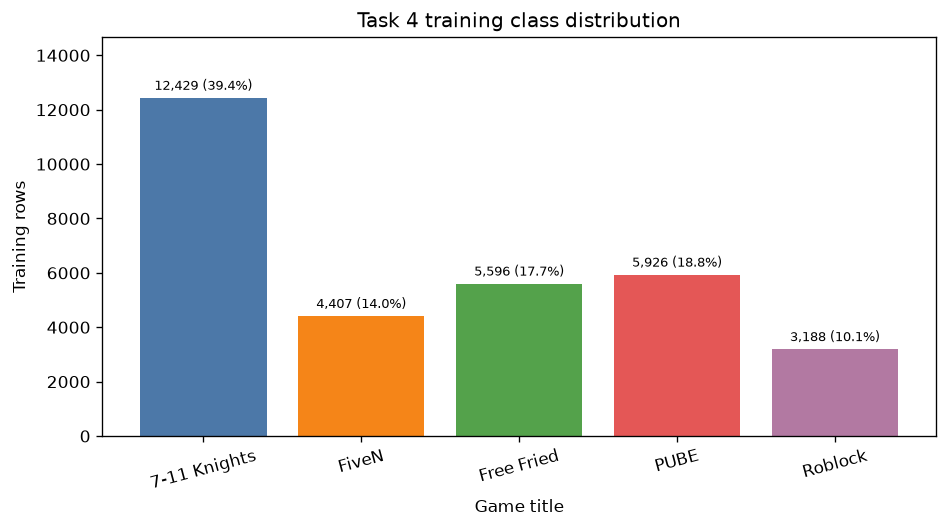

In [2]:
split_summary = pd.DataFrame(
    [
        {
            "split": "train",
            "rows": len(train),
            "unique_ids": train["id"].nunique(),
            "columns_loaded": ",".join(train.columns),
        },
        {
            "split": "test",
            "rows": len(test),
            "unique_ids": test["id"].nunique(),
            "columns_loaded": ",".join(test.columns),
        },
    ]
)
split_summary.to_csv(ASSETS_DIR / "split-summary.csv", index=False)

id_overlap = len(set(train["id"].astype(str)) & set(test["id"].astype(str)))
id_summary = pd.DataFrame(
    [
        {"check": "train_duplicate_ids", "count": int(train["id"].duplicated().sum())},
        {"check": "test_duplicate_ids", "count": int(test["id"].duplicated().sum())},
        {"check": "train_test_id_overlap", "count": id_overlap},
        {"check": "missing_train_labels", "count": int(train["class"].isna().sum())},
    ]
)
id_summary.to_csv(ASSETS_DIR / "id-integrity.csv", index=False)

counts = train["class"].value_counts().reindex(CLASS_ORDER, fill_value=0)
class_distribution = pd.DataFrame(
    {
        "class": CLASS_ORDER,
        "display_name": [CLASS_DISPLAY[label] for label in CLASS_ORDER],
        "count": counts.to_numpy(),
        "share": counts.to_numpy() / len(train),
    }
)
class_distribution.to_csv(ASSETS_DIR / "class-distribution.csv", index=False)
display(class_distribution)
print(
    f"Train/test ID overlap: {id_overlap:,}; class imbalance ratio (largest/smallest): {counts.max() / counts.min():.3f}"
)

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(
    class_distribution["display_name"],
    class_distribution["count"],
    color=["#4C78A8", "#F58518", "#54A24B", "#E45756", "#B279A2"],
)
ax.bar_label(
    bars,
    labels=[
        f"{count:,} ({share:.1%})"
        for count, share in zip(
            class_distribution["count"], class_distribution["share"], strict=True
        )
    ],
    padding=3,
    fontsize=8,
)
ax.set(
    title="Task 4 training class distribution",
    xlabel="Game title",
    ylabel="Training rows",
)
ax.tick_params(axis="x", rotation=15)
ax.margins(y=0.18)
fig.tight_layout()
fig.savefig(ASSETS_DIR / "class-distribution.png", dpi=300, bbox_inches="tight")
plt.show()

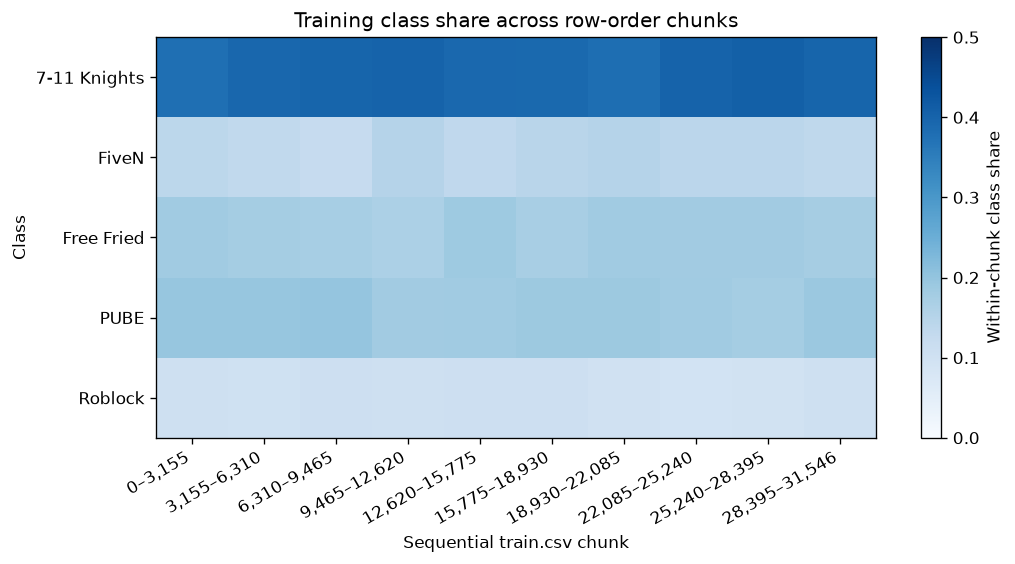

In [3]:
# Inspect whether class proportions drift over train.csv row order; this is diagnostic only.
chunk_size = math.ceil(len(train) / 10)
row_profiles = []
for start in range(0, len(train), chunk_size):
    chunk = train.iloc[start : start + chunk_size]
    proportions = (
        chunk["class"].value_counts(normalize=True).reindex(CLASS_ORDER, fill_value=0)
    )
    row_profiles.append(
        {"row_start": start, "row_end": start + len(chunk), **proportions.to_dict()}
    )
row_profile = pd.DataFrame(row_profiles)
row_profile.to_csv(ASSETS_DIR / "row-order-class-distribution.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 4.8))
image = ax.imshow(
    row_profile[CLASS_ORDER].to_numpy().T,
    aspect="auto",
    cmap="Blues",
    vmin=0,
    vmax=max(0.5, row_profile[CLASS_ORDER].to_numpy().max()),
)
ax.set(
    title="Training class share across row-order chunks",
    xlabel="Sequential train.csv chunk",
    ylabel="Class",
)
ax.set_yticks(range(len(CLASS_ORDER)), [CLASS_DISPLAY[label] for label in CLASS_ORDER])
ax.set_xticks(
    range(len(row_profile)),
    [
        f"{start:,}–{end:,}"
        for start, end in zip(
            row_profile["row_start"], row_profile["row_end"], strict=True
        )
    ],
    rotation=30,
    ha="right",
)
fig.colorbar(image, ax=ax, label="Within-chunk class share")
fig.tight_layout()
fig.savefig(
    ASSETS_DIR / "row-order-class-distribution.png", dpi=300, bbox_inches="tight"
)
plt.show()

In [4]:
def locate_image_dir(split):
    candidates = [
        DATA_DIR / split,
        DATA_DIR / f"{split}_images",
        DATA_DIR / "images" / split,
    ]
    return next((path for path in candidates if path.is_dir()), None)


def image_path(row, folder):
    name = row.get("file_name")
    filename = str(name) if pd.notna(name) and str(name).strip() else f"{row['id']}.jpg"
    path = Path(filename)
    return path if path.is_absolute() else folder / path


image_dirs = {split: locate_image_dir(split) for split in ["train", "test"]}
integrity_rows = []
image_records = []
for split, frame in [("train", train), ("test", test)]:
    folder = image_dirs[split]
    if folder is None:
        integrity_rows.append(
            {
                "split": split,
                "status": "image_folder_not_available",
                "sampled": 0,
                "readable": 0,
                "missing": 0,
                "corrupt": 0,
            }
        )
        continue
    sampled = frame.sample(n=min(1000, len(frame)), random_state=42)
    readable = 0
    missing = 0
    corrupt = 0
    for row in sampled.to_dict("records"):
        path = image_path(row, folder)
        if not path.is_file():
            missing += 1
            continue
        try:
            with Image.open(path) as image:
                image.verify()
            with Image.open(path) as image:
                image_records.append(
                    {
                        "split": split,
                        "id": str(row["id"]),
                        "width": image.width,
                        "height": image.height,
                        "mode": image.mode,
                        "bytes": path.stat().st_size,
                    }
                )
            readable += 1
        except (OSError, ValueError):
            corrupt += 1
    integrity_rows.append(
        {
            "split": split,
            "status": "sampled",
            "sampled": len(sampled),
            "readable": readable,
            "missing": missing,
            "corrupt": corrupt,
        }
    )

image_integrity = pd.DataFrame(integrity_rows)
image_integrity.to_csv(ASSETS_DIR / "image-integrity.csv", index=False)
print(image_integrity.to_string(index=False))
if image_records:
    image_info = pd.DataFrame(image_records)
    display(
        image_info.groupby(["split", "width", "height", "mode"])
        .size()
        .rename("sampled_images")
        .reset_index()
    )
    fig, axes = plt.subplots(1, 2, figsize=(9, 4))
    for split, ax in zip(["train", "test"], axes, strict=True):
        subset = image_info[image_info["split"] == split]
        ax.scatter(subset["width"], subset["height"], s=12, alpha=0.5)
        ax.set(
            title=f"{split.title()} image dimensions",
            xlabel="Width (px)",
            ylabel="Height (px)",
        )
    fig.tight_layout()
    fig.savefig(ASSETS_DIR / "image-dimensions.png", dpi=300, bbox_inches="tight")
    plt.show()
    image_info.to_csv(ASSETS_DIR / "image-sample-metadata.csv", index=False)
else:
    print(
        "No local image folders found; image-specific plots were skipped. The Kaggle training notebooks mount the images separately."
    )

split                     status  sampled  readable  missing  corrupt
train image_folder_not_available        0         0        0        0
 test image_folder_not_available        0         0        0        0
No local image folders found; image-specific plots were skipped. The Kaggle training notebooks mount the images separately.


In [5]:
train_image_dir = image_dirs["train"]
if train_image_dir is not None:
    image_rows = []
    for label in CLASS_ORDER:
        subset = train.loc[train["class"] == label].sample(
            n=min(4, int((train["class"] == label).sum())), random_state=42
        )
        image_rows.extend((label, row) for row in subset.to_dict("records"))
    fig, axes = plt.subplots(len(CLASS_ORDER), 4, figsize=(12, 12), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for row_idx, label in enumerate(CLASS_ORDER):
        for col_idx, (sample_label, row) in enumerate(
            [item for item in image_rows if item[0] == label]
        ):
            path = image_path(row, train_image_dir)
            if path.is_file():
                with Image.open(path) as image:
                    axes[row_idx, col_idx].imshow(image.convert("RGB"))
                axes[row_idx, col_idx].set_title(str(row["id"]), fontsize=7)
        axes[row_idx, 0].set_ylabel(CLASS_DISPLAY[label], rotation=90, fontsize=9)
    fig.suptitle("Representative training images by game", y=1.0)
    fig.tight_layout()
    fig.savefig(ASSETS_DIR / "representative-images.png", dpi=300, bbox_inches="tight")
    plt.show()

    rng = np.random.default_rng(42)
    color_rows = []
    for label in CLASS_ORDER:
        subset = train.loc[train["class"] == label].sample(
            n=min(50, int((train["class"] == label).sum())), random_state=42
        )
        for row in subset.to_dict("records"):
            path = image_path(row, train_image_dir)
            if path.is_file():
                with Image.open(path) as image:
                    pixels = np.asarray(image.convert("RGB"), dtype=np.float32) / 255.0
                means = pixels.mean(axis=(0, 1))
                color_rows.append(
                    {
                        "class": label,
                        "brightness": float(means.mean()),
                        "red": float(means[0]),
                        "green": float(means[1]),
                        "blue": float(means[2]),
                    }
                )
    color_summary = pd.DataFrame(color_rows)
    color_summary.to_csv(ASSETS_DIR / "color-sample.csv", index=False)
    if not color_summary.empty:
        color_means = (
            color_summary.groupby("class")[["red", "green", "blue"]]
            .mean()
            .reindex(CLASS_ORDER)
        )
        fig, axes = plt.subplots(1, 2, figsize=(10, 4))
        axes[0].boxplot(
            [
                color_summary.loc[color_summary["class"] == label, "brightness"]
                for label in CLASS_ORDER
            ],
            tick_labels=[CLASS_DISPLAY[label] for label in CLASS_ORDER],
            showfliers=False,
        )
        axes[0].set(
            title="Image brightness by game", ylabel="Mean normalized pixel value"
        )
        color_means.plot(
            kind="bar", ax=axes[1], color=["#E45756", "#54A24B", "#4C78A8"]
        )
        axes[1].set(
            title="Mean RGB channels by game",
            xlabel="Game title",
            ylabel="Mean normalized channel value",
        )
        axes[1].tick_params(axis="x", rotation=25)
        axes[1].legend(title="Channel")
        fig.tight_layout()
        fig.savefig(
            ASSETS_DIR / "color-distributions.png", dpi=300, bbox_inches="tight"
        )
        plt.show()
else:
    print(
        "No training image directory available; representative-image and color analyses were skipped."
    )

print(f"EDA tables and plots saved to {ASSETS_DIR.resolve()}")

No training image directory available; representative-image and color analyses were skipped.
EDA tables and plots saved to C:\Users\Gunte\Workspace\Workspace\works\CPE\ml00x\task4\assets\eda


## Interpretation and limits

- Training labels are used only for descriptive summaries and plots. Test is loaded with `id` and optional `file_name` only; no test labels are inspected.
- Image checks are deterministic samples (up to 1,000 files per split, plus up to 50 train images per class for color summaries), not a complete filesystem audit.
- The local checkout may contain CSV metadata without image files. In that case the notebook still produces metadata and class-distribution artifacts and reports which image analyses were skipped.